
Test MSE Comparison:
Transformer: 1.2997
SVM        : 1.0631


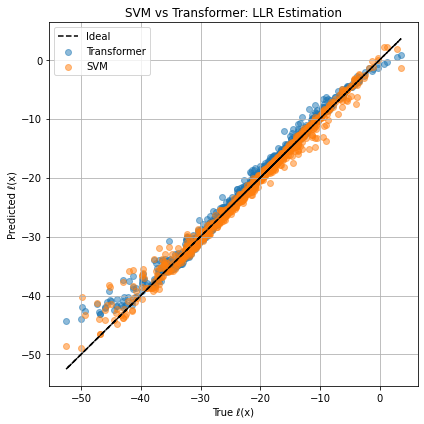

In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
import os

# ======= Log-Likelihood Ratio Function =======
def compute_true_llr(x, mu_p, mu_q, sigma_p, sigma_q):
    x = x.reshape((-1,))
    sigma_p_inv = np.linalg.inv(sigma_p)
    sigma_q_inv = np.linalg.inv(sigma_q)
    diff_p = x - mu_p
    diff_q = x - mu_q
    term_p = diff_p.T @ sigma_p_inv @ diff_p
    term_q = diff_q.T @ sigma_q_inv @ diff_q
    log_det_term = np.log(np.linalg.det(sigma_q) / np.linalg.det(sigma_p))
    return 0.5 * (term_q - term_p + log_det_term)

# ======= Dataset Generation =======
def generate_dataset(n, d, mu_p, mu_q, sigma_p, sigma_q):
    X, Y = [], []
    for _ in range(n):
        x = np.random.multivariate_normal(mu_q, sigma_q).astype(np.float32)
        y = compute_true_llr(x, mu_p, mu_q, sigma_p, sigma_q)
        X.append(x)
        Y.append(y)
    return np.array(X), np.array(Y)

# ======= Normalization =======
def normalize_targets(y_train, y_test):
    mean = np.mean(y_train)
    std = np.std(y_train)
    return (y_train - mean) / std, (y_test - mean) / std, mean, std

# ======= Transformer Model =======
class LLRTransformer(nn.Module):
    def __init__(self, d_input, d_model=64, num_layers=2):
        super(LLRTransformer, self).__init__()
        self.input_proj = nn.Linear(d_input, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=4)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.output_head = nn.Linear(d_model, 1)

    def forward(self, x):
        # x shape: (batch, d_input)
        x = self.input_proj(x).unsqueeze(0)  # (1, batch, d_model)
        x = self.transformer(x)              # (1, batch, d_model)
        x = x.squeeze(0)                     # (batch, d_model)
        return self.output_head(x).squeeze(1)  # (batch,)

# ======= Training Loop =======
def train_transformer(model, X_train, y_train, X_test, y_test, epochs=100):
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.float32)
    X_test = torch.tensor(X_test, dtype=torch.float32)

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.MSELoss()

    for _ in range(epochs):
        model.train()
        pred = model(X_train)
        loss = loss_fn(pred, y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        pred_test = model(X_test).numpy()
    return pred_test

# ======= Main Experiment =======
if __name__ == "__main__":
    d = 10
    n_train, n_test = 5000, 1000
    mu_p = np.ones(d, dtype=np.float32)
    mu_q = -np.ones(d, dtype=np.float32)
    sigma_p = np.eye(d, dtype=np.float32)
    sigma_q = 2 * np.eye(d, dtype=np.float32)

    X_train, y_train = generate_dataset(n_train, d, mu_p, mu_q, sigma_p, sigma_q)
    X_test, y_test = generate_dataset(n_test, d, mu_p, mu_q, sigma_p, sigma_q)
    y_train_norm, y_test_norm, mean_llr, std_llr = normalize_targets(y_train, y_test)

    # SVM
    svr = SVR(kernel='rbf', C=1.0, epsilon=0.1)
    svr.fit(X_train, y_train_norm)
    pred_svr_norm = svr.predict(X_test)
    pred_svr = pred_svr_norm * std_llr + mean_llr
    mse_svr = mean_squared_error(y_test, pred_svr)

    # Transformer
    model = LLRTransformer(d_input=d)
    pred_trans_norm = train_transformer(model, X_train, y_train_norm, X_test, y_test_norm)
    pred_trans = pred_trans_norm * std_llr + mean_llr
    mse_trans = mean_squared_error(y_test, pred_trans)

    print("\nTest MSE Comparison:")
    print("Transformer: {:.4f}".format(mse_trans))
    print("SVM        : {:.4f}".format(mse_svr))

    # Plot
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, pred_trans, alpha=0.5, label="Transformer")
    plt.scatter(y_test, pred_svr, alpha=0.5, label="SVM")
    plt.plot(y_test, y_test, 'k--', label="Ideal")
    plt.xlabel("True ℓ(x)")
    plt.ylabel("Predicted ℓ(x)")
    plt.title("SVM vs Transformer: LLR Estimation")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    os.makedirs("../results", exist_ok=True)
    plt.savefig("../results/transformer_vs_svm_estimator_learning.png", dpi=300, bbox_inches='tight')
    plt.show()



MSE on Case 1 (Linear LLR):
SVM         : 0.4278
MLP         : 13.2129
Transformer : 0.3713


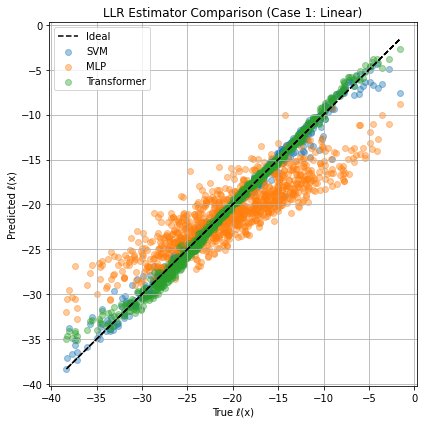

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error

# ======= True Linear LLR for Case 1 =======
def compute_linear_llr(x, mu):
    return 2 * np.dot(mu, x)

# ======= Dataset Generation =======
def generate_case1_data(n, d, mu):
    # P = N(mu, I), Q = N(-mu, I), so sample x ~ Q
    X = np.random.multivariate_normal(-mu, np.eye(d), size=n).astype(np.float32)
    Y = np.array([compute_linear_llr(x, mu) for x in X])
    return X, Y

# ======= Normalization =======
def normalize(y_train, y_test):
    mean = np.mean(y_train)
    std = np.std(y_train)
    return (y_train - mean)/std, (y_test - mean)/std, mean, std

# ======= MLP =======
class MLP(nn.Module):
    def __init__(self, d_in, d_hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, d_hidden),
            nn.ReLU(),
            nn.Linear(d_hidden, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze()

# ======= Transformer =======
class LLRTransformer(nn.Module):
    def __init__(self, d_in, d_model=64):
        super().__init__()
        self.input_proj = nn.Linear(d_in, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=4)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=2)
        self.out = nn.Linear(d_model, 1)
    def forward(self, x):  # x: (B, d)
        x = self.input_proj(x).unsqueeze(0)      # (1, B, d_model)
        x = self.encoder(x).squeeze(0)            # (B, d_model)
        return self.out(x).squeeze()

# ======= Train Wrapper =======
def train_model(model, X_train, y_train, X_test, epochs=100, lr=1e-3):
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.float32)
    X_test  = torch.tensor(X_test, dtype=torch.float32)

    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    for _ in range(epochs):
        model.train()
        pred = model(X_train)
        loss = loss_fn(pred, y_train)
        opt.zero_grad()
        loss.backward()
        opt.step()

    model.eval()
    with torch.no_grad():
        return model(X_test).numpy()

# ======= Main: Case 1 =======
if __name__ == "__main__":
    d = 10
    n_train, n_test = 5000, 1000
    mu = np.ones(d, dtype=np.float32)

    X_train, y_train = generate_case1_data(n_train, d, mu)
    X_test,  y_test  = generate_case1_data(n_test,  d, mu)
    y_train_n, y_test_n, mean, std = normalize(y_train, y_test)

    # === SVM ===
    svr = SVR()
    svr.fit(X_train, y_train_n)
    pred_svr_n = svr.predict(X_test)
    pred_svr = pred_svr_n * std + mean
    mse_svr = mean_squared_error(y_test, pred_svr)

    # === MLP ===
    mlp = MLP(d)
    pred_mlp_n = train_model(mlp, X_train, y_train_n, X_test)
    pred_mlp = pred_mlp_n * std + mean
    mse_mlp = mean_squared_error(y_test, pred_mlp)

    # === Transformer ===
    transformer = LLRTransformer(d)
    pred_trans_n = train_model(transformer, X_train, y_train_n, X_test)
    pred_trans = pred_trans_n * std + mean
    mse_trans = mean_squared_error(y_test, pred_trans)

    # === Results ===
    print("\nMSE on Case 1 (Linear LLR):")
    print(f"SVM         : {mse_svr:.4f}")
    print(f"MLP         : {mse_mlp:.4f}")
    print(f"Transformer : {mse_trans:.4f}")

    # === Scatter Plot ===
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, pred_svr, alpha=0.4, label="SVM")
    plt.scatter(y_test, pred_mlp, alpha=0.4, label="MLP")
    plt.scatter(y_test, pred_trans, alpha=0.4, label="Transformer")
    plt.plot(y_test, y_test, 'k--', label="Ideal")
    plt.xlabel("True ℓ(x)")
    plt.ylabel("Predicted ℓ(x)")
    plt.title("LLR Estimator Comparison (Case 1: Linear)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    os.makedirs("../results", exist_ok=True)
    plt.savefig("../results/transformer_vs_svm_vs_NN_estimator_learning.png", dpi=300, bbox_inches='tight')
    plt.show()


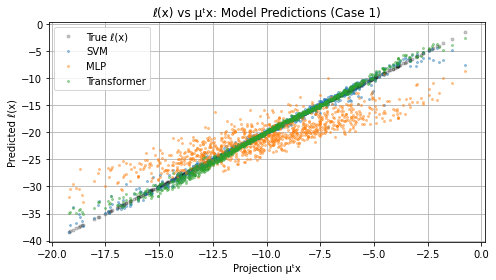

In [4]:
# === Plot Predicted ℓ(x) vs μᵗx (1D curve)
s_proj = X_test @ mu  # shape (n_test,)
true_llr = y_test

plt.figure(figsize=(7, 4))
plt.plot(s_proj, true_llr, 'k.', alpha=0.2, label='True ℓ(x)')
plt.plot(s_proj, pred_svr, 'o', markersize=2, alpha=0.4, label='SVM')
plt.plot(s_proj, pred_mlp, 'o', markersize=2, alpha=0.4, label='MLP')
plt.plot(s_proj, pred_trans, 'o', markersize=2, alpha=0.4, label='Transformer')
plt.xlabel("Projection μᵗx")
plt.ylabel("Predicted ℓ(x)")
plt.title("ℓ(x) vs μᵗx: Model Predictions (Case 1)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



MSE on Case 2 (Variance Shift):
SVM         : 0.0609
MLP         : 2.7789
Transformer : 0.1646


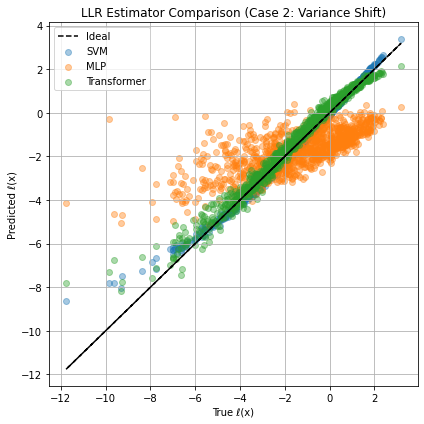

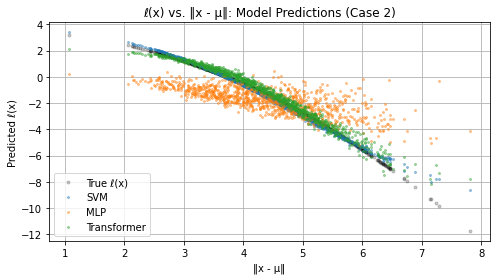

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error

# ======= True Nonlinear LLR for Case 2 =======
def compute_quadratic_llr(x, mu, d):
    diff = x - mu
    norm_sq = np.dot(diff, diff)
    return -0.25 * norm_sq + 0.5 * d * np.log(2)

# ======= Dataset Generation =======
def generate_case2_data(n, d, mu):
    # P = N(mu, I), Q = N(mu, 2I) → sample from Q
    X = np.random.multivariate_normal(mu, 2 * np.eye(d), size=n).astype(np.float32)
    Y = np.array([compute_quadratic_llr(x, mu, d) for x in X])
    return X, Y

# ======= Normalization =======
def normalize(y_train, y_test):
    mean = np.mean(y_train)
    std = np.std(y_train)
    return (y_train - mean)/std, (y_test - mean)/std, mean, std

# ======= MLP =======
class MLP(nn.Module):
    def __init__(self, d_in, d_hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, d_hidden),
            nn.ReLU(),
            nn.Linear(d_hidden, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze()

# ======= Transformer =======
class LLRTransformer(nn.Module):
    def __init__(self, d_in, d_model=64):
        super().__init__()
        self.input_proj = nn.Linear(d_in, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=4)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=2)
        self.out = nn.Linear(d_model, 1)
    def forward(self, x):  # x: (B, d)
        x = self.input_proj(x).unsqueeze(0)      # (1, B, d_model)
        x = self.encoder(x).squeeze(0)            # (B, d_model)
        return self.out(x).squeeze()

# ======= Train Wrapper =======
def train_model(model, X_train, y_train, X_test, epochs=100, lr=1e-3):
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.float32)
    X_test  = torch.tensor(X_test, dtype=torch.float32)

    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    for _ in range(epochs):
        model.train()
        pred = model(X_train)
        loss = loss_fn(pred, y_train)
        opt.zero_grad()
        loss.backward()
        opt.step()

    model.eval()
    with torch.no_grad():
        return model(X_test).numpy()

# ======= Main: Case 2 =======
if __name__ == "__main__":
    d = 10
    n_train, n_test = 5000, 1000
    mu = np.ones(d, dtype=np.float32)

    X_train, y_train = generate_case2_data(n_train, d, mu)
    X_test,  y_test  = generate_case2_data(n_test,  d, mu)
    y_train_n, y_test_n, mean, std = normalize(y_train, y_test)

    # === SVM ===
    svr = SVR()
    svr.fit(X_train, y_train_n)
    pred_svr_n = svr.predict(X_test)
    pred_svr = pred_svr_n * std + mean
    mse_svr = mean_squared_error(y_test, pred_svr)

    # === MLP ===
    mlp = MLP(d)
    pred_mlp_n = train_model(mlp, X_train, y_train_n, X_test)
    pred_mlp = pred_mlp_n * std + mean
    mse_mlp = mean_squared_error(y_test, pred_mlp)

    # === Transformer ===
    transformer = LLRTransformer(d)
    pred_trans_n = train_model(transformer, X_train, y_train_n, X_test)
    pred_trans = pred_trans_n * std + mean
    mse_trans = mean_squared_error(y_test, pred_trans)

    # === Results ===
    print("\nMSE on Case 2 (Variance Shift):")
    print(f"SVM         : {mse_svr:.4f}")
    print(f"MLP         : {mse_mlp:.4f}")
    print(f"Transformer : {mse_trans:.4f}")

    # === Scatter Plot ===
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, pred_svr, alpha=0.4, label="SVM")
    plt.scatter(y_test, pred_mlp, alpha=0.4, label="MLP")
    plt.scatter(y_test, pred_trans, alpha=0.4, label="Transformer")
    plt.plot(y_test, y_test, 'k--', label="Ideal")
    plt.xlabel("True ℓ(x)")
    plt.ylabel("Predicted ℓ(x)")
    plt.title("LLR Estimator Comparison (Case 2: Variance Shift)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # === Plot ℓ(x) vs. ‖x - μ‖ ===
    x_norm = np.linalg.norm(X_test - mu, axis=1)

    plt.figure(figsize=(7, 4))
    plt.plot(x_norm, y_test, 'k.', alpha=0.2, label='True ℓ(x)')
    plt.plot(x_norm, pred_svr, 'o', markersize=2, alpha=0.4, label='SVM')
    plt.plot(x_norm, pred_mlp, 'o', markersize=2, alpha=0.4, label='MLP')
    plt.plot(x_norm, pred_trans, 'o', markersize=2, alpha=0.4, label='Transformer')
    plt.xlabel("‖x - μ‖")
    plt.ylabel("Predicted ℓ(x)")
    plt.title("ℓ(x) vs. ‖x - μ‖: Model Predictions (Case 2)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    os.makedirs("../results", exist_ok=True)
    plt.savefig("../results/transformer_vs_svm_vs_NN_estimator_learning_under_shift.png", dpi=300, bbox_inches='tight')
    plt.show()



MSE on Case 3 (Mixture vs Gaussian):
SVM         : 0.1459
MLP         : 1.0359
Transformer : 0.0334


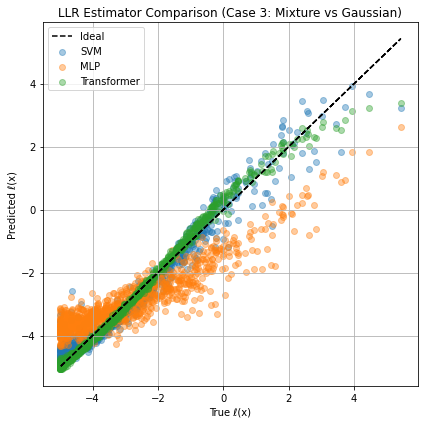

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
from scipy.stats import multivariate_normal

# ======= True LLR for Case 3 (Mixture vs Gaussian) =======
def compute_mixture_llr(x, mu, d):
    # P = 0.5 N(mu, I) + 0.5 N(-mu, I)
    # Q = N(0, I)
    cov = np.eye(d)
    p1 = multivariate_normal.pdf(x, mean=mu, cov=cov)
    p2 = multivariate_normal.pdf(x, mean=-mu, cov=cov)
    q  = multivariate_normal.pdf(x, mean=np.zeros(d), cov=cov)
    return np.log(0.5 * (p1 + p2) / q)

# ======= Dataset Generation =======
def generate_case3_data(n, d, mu):
    X = np.random.multivariate_normal(np.zeros(d), np.eye(d), size=n).astype(np.float32)
    Y = np.array([compute_mixture_llr(x, mu, d) for x in X])
    return X, Y

# ======= Normalization =======
def normalize(y_train, y_test):
    mean = np.mean(y_train)
    std = np.std(y_train)
    return (y_train - mean)/std, (y_test - mean)/std, mean, std

# ======= MLP =======
class MLP(nn.Module):
    def __init__(self, d_in, d_hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, d_hidden),
            nn.ReLU(),
            nn.Linear(d_hidden, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze()

# ======= Transformer =======
class LLRTransformer(nn.Module):
    def __init__(self, d_in, d_model=64):
        super().__init__()
        self.input_proj = nn.Linear(d_in, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=4)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=2)
        self.out = nn.Linear(d_model, 1)
    def forward(self, x):
        x = self.input_proj(x).unsqueeze(0)
        x = self.encoder(x).squeeze(0)
        return self.out(x).squeeze()

# ======= Train Wrapper =======
def train_model(model, X_train, y_train, X_test, epochs=100, lr=1e-3):
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.float32)
    X_test  = torch.tensor(X_test, dtype=torch.float32)

    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    for _ in range(epochs):
        model.train()
        pred = model(X_train)
        loss = loss_fn(pred, y_train)
        opt.zero_grad()
        loss.backward()
        opt.step()

    model.eval()
    with torch.no_grad():
        return model(X_test).numpy()

# ======= Main: Case 3 =======
if __name__ == "__main__":
    d = 10
    n_train, n_test = 5000, 1000
    mu = np.ones(d, dtype=np.float32)

    X_train, y_train = generate_case3_data(n_train, d, mu)
    X_test,  y_test  = generate_case3_data(n_test,  d, mu)
    y_train_n, y_test_n, mean, std = normalize(y_train, y_test)

    # === SVM ===
    svr = SVR()
    svr.fit(X_train, y_train_n)
    pred_svr_n = svr.predict(X_test)
    pred_svr = pred_svr_n * std + mean
    mse_svr = mean_squared_error(y_test, pred_svr)

    # === MLP ===
    mlp = MLP(d)
    pred_mlp_n = train_model(mlp, X_train, y_train_n, X_test)
    pred_mlp = pred_mlp_n * std + mean
    mse_mlp = mean_squared_error(y_test, pred_mlp)

    # === Transformer ===
    transformer = LLRTransformer(d)
    pred_trans_n = train_model(transformer, X_train, y_train_n, X_test)
    pred_trans = pred_trans_n * std + mean
    mse_trans = mean_squared_error(y_test, pred_trans)

    # === Results ===
    print("\nMSE on Case 3 (Mixture vs Gaussian):")
    print(f"SVM         : {mse_svr:.4f}")
    print(f"MLP         : {mse_mlp:.4f}")
    print(f"Transformer : {mse_trans:.4f}")

    # === Scatter Plot ===
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, pred_svr, alpha=0.4, label="SVM")
    plt.scatter(y_test, pred_mlp, alpha=0.4, label="MLP")
    plt.scatter(y_test, pred_trans, alpha=0.4, label="Transformer")
    plt.plot(y_test, y_test, 'k--', label="Ideal")
    plt.xlabel("True ℓ(x)")
    plt.ylabel("Predicted ℓ(x)")
    plt.title("LLR Estimator Comparison (Case 3: Mixture vs Gaussian)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


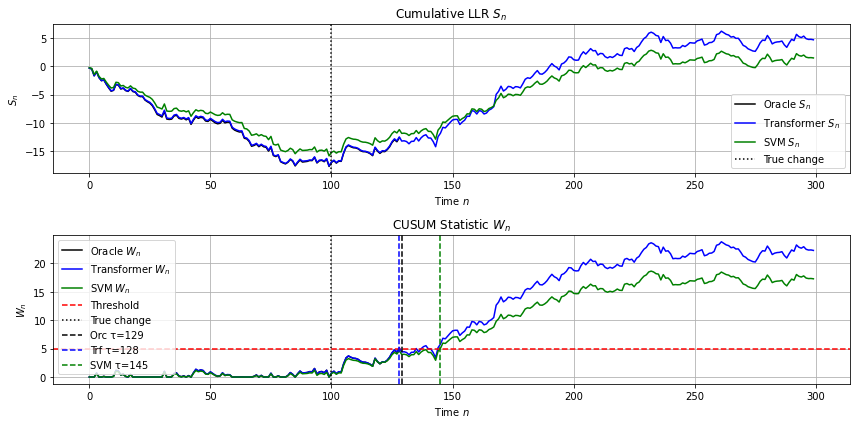

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import torch
import torch.nn as nn
from sklearn.svm import SVR

# ======= CUSUM wrapper =======
class CUSUM:
    def __init__(self, f0, f1, threshold):
        self.f0 = f0
        self.f1 = f1
        self.b = threshold

    def run(self, x):
        S, W = [], []
        s, w = 0.0, 0.0
        for xi in x:
            llr = np.log(self.f1(xi) / self.f0(xi))
            s += llr
            w = max(0, w + llr)
            S.append(s)
            W.append(w)
            if w >= self.b:
                return W, S, len(W)
        return W, S, None

# ======= Transformer model =======
class SimpleTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze()

# ======= MLP training =======
def train_model(model, X, y, epochs=100, lr=1e-3):
    X = torch.tensor(X, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    for _ in range(epochs):
        model.train()
        pred = model(X)
        loss = loss_fn(pred, y)
        opt.zero_grad()
        loss.backward()
        opt.step()
    return model

# ======= Recursive W_n =======
def compute_W(llr, threshold):
    W = np.zeros_like(llr)
    tau = None
    for n in range(1, len(llr)):
        W[n] = max(0, W[n-1] + llr[n])
        if tau is None and W[n] >= threshold:
            tau = n
    return W, tau

# ======= Run for Oracle, SVM, Transformer =======
if __name__ == "__main__":
    np.random.seed(2)
    n_pre, n_post = 100, 200
    mu0, mu1, sigma = 0, 0.5, 1
    x = np.concatenate([
        np.random.normal(mu0, sigma, n_pre),
        np.random.normal(mu1, sigma, n_post)
    ])

    f0 = lambda x: norm.pdf(x, mu0, sigma)
    f1 = lambda x: norm.pdf(x, mu1, sigma)
    threshold = 5.0

    # === Oracle ===
    oracle = CUSUM(f0, f1, threshold)
    W_or, S_or, tau_or = oracle.run(x)

    # === Train LLR Estimators ===
    n_train = 5000
    X_train = np.random.normal(mu0, sigma, size=(n_train, 1))
    y_train = np.log(norm.pdf(X_train, mu1, sigma) / norm.pdf(X_train, mu0, sigma)).squeeze()

    # --- SVM ---
    svm = SVR().fit(X_train, y_train)
    llr_svm = svm.predict(x.reshape(-1, 1))
    S_svm = np.cumsum(llr_svm)
    W_svm, tau_svm = compute_W(llr_svm, threshold)

    # --- Transformer ---
    transformer = train_model(SimpleTransformer(), X_train, y_train)
    with torch.no_grad():
        llr_trans = transformer(torch.tensor(x.reshape(-1, 1), dtype=torch.float32)).numpy()
    S_trans = np.cumsum(llr_trans)
    W_trans, tau_trans = compute_W(llr_trans, threshold)

    # === Plotting ===
    plt.figure(figsize=(12, 6))

    plt.subplot(2, 1, 1)
    plt.plot(S_or, label='Oracle $S_n$', color='black')
    plt.plot(S_trans, label='Transformer $S_n$', color='blue')
    plt.plot(S_svm, label='SVM $S_n$', color='green')
    plt.axvline(n_pre, color='k', linestyle=':', label='True change')
    plt.title('Cumulative LLR $S_n$')
    plt.xlabel('Time $n$')
    plt.ylabel('$S_n$')
    plt.grid(True)
    plt.legend()

    plt.subplot(2, 1, 2)
    plt.plot(W_or, label='Oracle $W_n$', color='black')
    plt.plot(W_trans, label='Transformer $W_n$', color='blue')
    plt.plot(W_svm, label='SVM $W_n$', color='green')
    plt.axhline(threshold, color='red', linestyle='--', label='Threshold')
    plt.axvline(n_pre, color='k', linestyle=':', label='True change')
    if tau_or:
        plt.axvline(tau_or, color='black', linestyle='--', label=f'Orc τ={tau_or}')
    if tau_trans:
        plt.axvline(tau_trans, color='blue', linestyle='--', label=f'Trf τ={tau_trans}')
    if tau_svm:
        plt.axvline(tau_svm, color='green', linestyle='--', label=f'SVM τ={tau_svm}')
    plt.title('CUSUM Statistic $W_n$')
    plt.xlabel('Time $n$')
    plt.ylabel('$W_n$')
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    os.makedirs("../results", exist_ok=True)
    plt.savefig("../results/transformer_wn_curve.png", dpi=300, bbox_inches='tight')
    plt.show()


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.svm import SVR
from scipy.stats import norm
from sklearn.metrics.pairwise import rbf_kernel
from scipy.optimize import minimize

# ==== RKHS LLR Estimator ====
class RKHSLikelihoodRatioEstimator:
    def __init__(self, sigma=1.0, lambda_reg=1e-2):
        self.sigma = sigma
        self.lambda_reg = lambda_reg
        self.alpha = None
        self.X_p = None

    def _compute_kernel_matrices(self, X_p, X_q):
        gamma = 1.0 / (2 * self.sigma ** 2)
        K_PP = rbf_kernel(X_p[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
        K_QP = rbf_kernel(X_q[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
        return K_PP, K_QP

    def _loss(self, alpha, K_PP, K_QP):
        g_q = K_QP @ alpha
        g_p = K_PP @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        return np.mean(g_q) - np.mean(np.log(g_p)) + 0.5 * self.lambda_reg * alpha @ K_PP @ alpha

    def _grad(self, alpha, K_PP, K_QP):
        g_p = K_PP @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        grad_q = np.mean(K_QP, axis=0)
        grad_p = -(K_PP @ (1.0 / g_p)) / K_PP.shape[0]
        return grad_q + grad_p + self.lambda_reg * (K_PP @ alpha)

    def fit(self, X_p, X_q):
        self.X_p = X_p
        K_PP, K_QP = self._compute_kernel_matrices(X_p, X_q)
        n_p = X_p.shape[0]
        alpha0 = np.ones(n_p) / n_p
        bounds = [(0, None)] * n_p
        result = minimize(
            fun=lambda a: self._loss(a, K_PP, K_QP),
            x0=alpha0,
            jac=lambda a: self._grad(a, K_PP, K_QP),
            method='L-BFGS-B',
            bounds=bounds,
            options={'maxiter': 500, 'ftol': 1e-9}
        )
        self.alpha = result.x

    def predict_log(self, X):
        gamma = 1.0 / (2 * self.sigma ** 2)
        K = rbf_kernel(X[:, np.newaxis], self.X_p[:, np.newaxis], gamma=gamma)
        return np.log(np.clip(K @ self.alpha, 1e-8, None))


# ==== Transformer model ====
class SimpleTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze()

# ==== Training ====
def train_model(model, X, y, epochs=100, lr=1e-3):
    X = torch.tensor(X, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    for _ in range(epochs):
        model.train()
        pred = model(X)
        loss = loss_fn(pred, y)
        opt.zero_grad()
        loss.backward()
        opt.step()
    return model

# ==== CUSUM run ====
def run_cusum(llrs, threshold):
    W = np.zeros(len(llrs))
    for n in range(1, len(llrs)):
        W[n] = max(0, W[n-1] + llrs[n])
    return W

# ==== Main experiment ====
np.random.seed(2)
n_pre, n_post = 100, 200
mu0, mu1, sigma = 0, 1, 1
x = np.concatenate([
    np.random.normal(mu0, sigma, n_pre),
    np.random.normal(mu1, sigma, n_post)
])

f0 = lambda x: norm.pdf(x, mu0, sigma)
f1 = lambda x: norm.pdf(x, mu1, sigma)
threshold = 5.0

# Oracle log-likelihoods
llr_oracle = np.log(f1(x) / f0(x))
W_oracle = run_cusum(llr_oracle, threshold)

# RKHS-based estimator
X_p = np.random.normal(mu1, sigma, size=500)
X_q = np.random.normal(mu0, sigma, size=500)
rkhs = RKHSLikelihoodRatioEstimator(sigma=1.0, lambda_reg=1e-2)
rkhs.fit(X_p, X_q)
llr_rkhs = rkhs.predict_log(x)
W_rkhs = run_cusum(llr_rkhs, threshold)

# Train Transformer and SVM on synthetic LLRs
X_train = np.random.normal(mu0, sigma, size=(2000, 1))
y_train = np.log(norm.pdf(X_train, mu1, sigma) / norm.pdf(X_train, mu0, sigma)).squeeze()

# SVM
svm = SVR().fit(X_train, y_train)
llr_svm = svm.predict(x.reshape(-1, 1))
W_svm = run_cusum(llr_svm, threshold)

# Transformer
transformer = train_model(SimpleTransformer(), X_train, y_train)
with torch.no_grad():
    llr_trans = transformer(torch.tensor(x.reshape(-1, 1), dtype=torch.float32)).numpy()
W_trans = run_cusum(llr_trans, threshold)

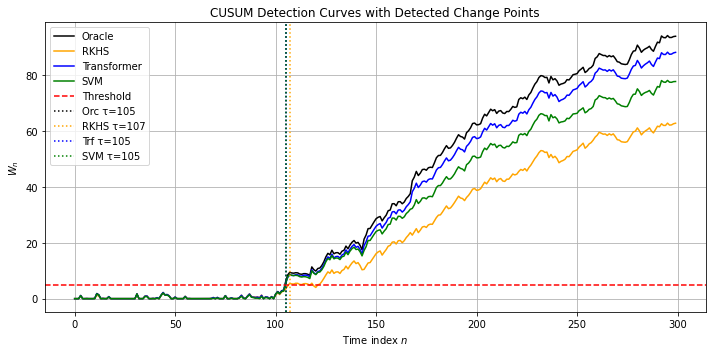

In [9]:
# ==== Detection points ====
tau_oracle = np.argmax(W_oracle >= threshold) if np.any(W_oracle >= threshold) else None
tau_rkhs = np.argmax(W_rkhs >= threshold) if np.any(W_rkhs >= threshold) else None
tau_trans = np.argmax(W_trans >= threshold) if np.any(W_trans >= threshold) else None
tau_svm = np.argmax(W_svm >= threshold) if np.any(W_svm >= threshold) else None

# ==== Plot Wn curves ====
plt.figure(figsize=(10, 5))
plt.plot(W_oracle, label="Oracle", color='black')
plt.plot(W_rkhs, label="RKHS", color='orange')
plt.plot(W_trans, label="Transformer", color='blue')
plt.plot(W_svm, label="SVM", color='green')
plt.axhline(threshold, color='red', linestyle='--', label='Threshold')

# Add detection point markers
if tau_oracle is not None:
    plt.axvline(tau_oracle, color='black', linestyle=':', label=f'Orc τ={tau_oracle}')
if tau_rkhs is not None:
    plt.axvline(tau_rkhs, color='orange', linestyle=':', label=f'RKHS τ={tau_rkhs}')
if tau_trans is not None:
    plt.axvline(tau_trans, color='blue', linestyle=':', label=f'Trf τ={tau_trans}')
if tau_svm is not None:
    plt.axvline(tau_svm, color='green', linestyle=':', label=f'SVM τ={tau_svm}')

plt.xlabel("Time index $n$")
plt.ylabel("$W_n$")
plt.title("CUSUM Detection Curves with Detected Change Points")
plt.grid(True)
plt.legend()
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/all_model_comparision.png", dpi=300, bbox_inches='tight')
plt.show()


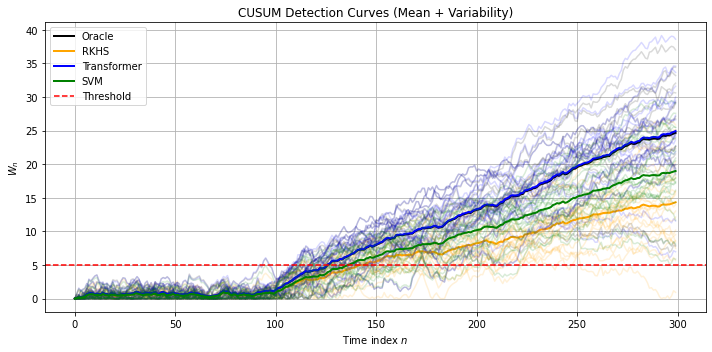

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.svm import SVR
from scipy.stats import norm
from sklearn.metrics.pairwise import rbf_kernel
from scipy.optimize import minimize

# ==== RKHS LLR Estimator ====
class RKHSLikelihoodRatioEstimator:
    def __init__(self, sigma=1.0, lambda_reg=1e-2):
        self.sigma = sigma
        self.lambda_reg = lambda_reg
        self.alpha = None
        self.X_p = None

    def _compute_kernel_matrices(self, X_p, X_q):
        gamma = 1.0 / (2 * self.sigma ** 2)
        K_PP = rbf_kernel(X_p[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
        K_QP = rbf_kernel(X_q[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
        return K_PP, K_QP

    def _loss(self, alpha, K_PP, K_QP):
        g_q = K_QP @ alpha
        g_p = K_PP @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        return np.mean(g_q) - np.mean(np.log(g_p)) + 0.5 * self.lambda_reg * alpha @ K_PP @ alpha

    def _grad(self, alpha, K_PP, K_QP):
        g_p = K_PP @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        grad_q = np.mean(K_QP, axis=0)
        grad_p = -(K_PP @ (1.0 / g_p)) / K_PP.shape[0]
        return grad_q + grad_p + self.lambda_reg * (K_PP @ alpha)

    def fit(self, X_p, X_q):
        self.X_p = X_p
        K_PP, K_QP = self._compute_kernel_matrices(X_p, X_q)
        n_p = X_p.shape[0]
        alpha0 = np.ones(n_p) / n_p
        bounds = [(0, None)] * n_p
        result = minimize(
            fun=lambda a: self._loss(a, K_PP, K_QP),
            x0=alpha0,
            jac=lambda a: self._grad(a, K_PP, K_QP),
            method='L-BFGS-B',
            bounds=bounds,
            options={'maxiter': 500, 'ftol': 1e-9}
        )
        self.alpha = result.x

    def predict_log(self, X):
        gamma = 1.0 / (2 * self.sigma ** 2)
        K = rbf_kernel(X[:, np.newaxis], self.X_p[:, np.newaxis], gamma=gamma)
        return np.log(np.clip(K @ self.alpha, 1e-8, None))

# ==== Transformer model ====
class SimpleTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze()

# ==== Training ====
def train_model(model, X, y, epochs=100, lr=1e-3):
    X = torch.tensor(X, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    for _ in range(epochs):
        model.train()
        pred = model(X)
        loss = loss_fn(pred, y)
        opt.zero_grad()
        loss.backward()
        opt.step()
    return model

# ==== CUSUM run ====
def run_cusum(llrs, threshold):
    W = np.zeros(len(llrs))
    for n in range(1, len(llrs)):
        W[n] = max(0, W[n-1] + llrs[n])
    return W

# ==== Repeat Experiment ====
def repeat_experiment(n_runs=20):
    n_pre, n_post = 100, 200
    mu0, mu1, sigma = 0, 0.5, 1
    threshold = 5.0

    all_W_oracle, all_W_rkhs, all_W_trans, all_W_svm = [], [], [], []

    for _ in range(n_runs):
        x = np.concatenate([
            np.random.normal(mu0, sigma, n_pre),
            np.random.normal(mu1, sigma, n_post)
        ])

        f0 = lambda x: norm.pdf(x, mu0, sigma)
        f1 = lambda x: norm.pdf(x, mu1, sigma)
        llr_oracle = np.log(f1(x) / f0(x))
        W_oracle = run_cusum(llr_oracle, threshold)

        X_p = np.random.normal(mu1, sigma, size=500)
        X_q = np.random.normal(mu0, sigma, size=500)
        rkhs = RKHSLikelihoodRatioEstimator()
        rkhs.fit(X_p, X_q)
        llr_rkhs = rkhs.predict_log(x)
        W_rkhs = run_cusum(llr_rkhs, threshold)

        X_train = np.random.normal(mu0, sigma, size=(2000, 1))
        y_train = np.log(norm.pdf(X_train, mu1, sigma) / norm.pdf(X_train, mu0, sigma)).squeeze()

        svm = SVR().fit(X_train, y_train)
        llr_svm = svm.predict(x.reshape(-1, 1))
        W_svm = run_cusum(llr_svm, threshold)

        transformer = train_model(SimpleTransformer(), X_train, y_train)
        with torch.no_grad():
            llr_trans = transformer(torch.tensor(x.reshape(-1, 1), dtype=torch.float32)).numpy()
        W_trans = run_cusum(llr_trans, threshold)

        all_W_oracle.append(W_oracle)
        all_W_rkhs.append(W_rkhs)
        all_W_trans.append(W_trans)
        all_W_svm.append(W_svm)

    return all_W_oracle, all_W_rkhs, all_W_trans, all_W_svm, threshold

# ==== Run & Plot ====
oracle_curves, rkhs_curves, trans_curves, svm_curves, threshold = repeat_experiment(n_runs=20)
max_len = max(map(len, oracle_curves))

def pad_and_plot(curves, label, color):
    for w in curves:
        w_pad = np.pad(w, (0, max_len - len(w)), constant_values=w[-1])
        plt.plot(w_pad, color=color, alpha=0.15)
    avg = np.mean([np.pad(w, (0, max_len - len(w)), constant_values=w[-1]) for w in curves], axis=0)
    plt.plot(avg, color=color, label=label, linewidth=2)

plt.figure(figsize=(10, 5))
pad_and_plot(oracle_curves, "Oracle", "black")
pad_and_plot(rkhs_curves, "RKHS", "orange")
pad_and_plot(trans_curves, "Transformer", "blue")
pad_and_plot(svm_curves, "SVM", "green")
plt.axhline(threshold, color='red', linestyle='--', label='Threshold')
plt.xlabel("Time index $n$")
plt.ylabel("$W_n$")
plt.title("CUSUM Detection Curves (Mean + Variability)")
plt.grid(True)
plt.legend()
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/all_models_multiruns.png", dpi=300, bbox_inches='tight')
plt.show()


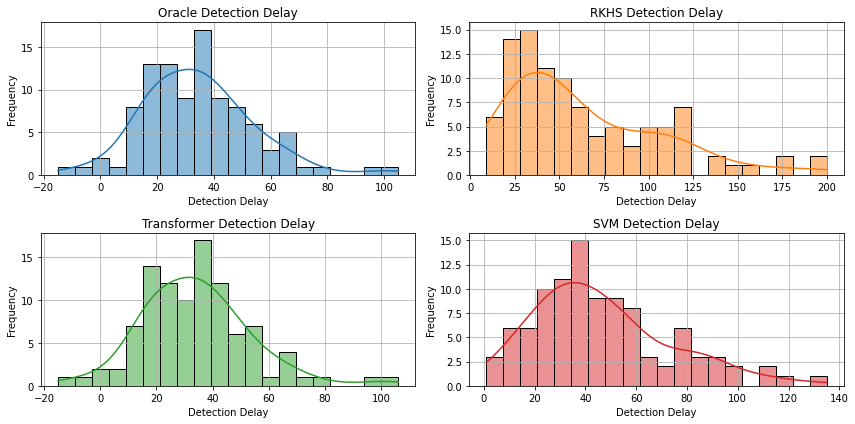

In [11]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.svm import SVR
from scipy.stats import norm
from sklearn.metrics.pairwise import rbf_kernel
from scipy.optimize import minimize

# ==== RKHS LLR Estimator ====
class RKHSLikelihoodRatioEstimator:
    def __init__(self, sigma=1.0, lambda_reg=1e-2):
        self.sigma = sigma
        self.lambda_reg = lambda_reg
        self.alpha = None
        self.X_p = None

    def _compute_kernel_matrices(self, X_p, X_q):
        gamma = 1.0 / (2 * self.sigma ** 2)
        K_PP = rbf_kernel(X_p[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
        K_QP = rbf_kernel(X_q[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
        return K_PP, K_QP

    def _loss(self, alpha, K_PP, K_QP):
        g_q = K_QP @ alpha
        g_p = K_PP @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        return np.mean(g_q) - np.mean(np.log(g_p)) + 0.5 * self.lambda_reg * alpha @ K_PP @ alpha

    def _grad(self, alpha, K_PP, K_QP):
        g_p = K_PP @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        grad_q = np.mean(K_QP, axis=0)
        grad_p = -(K_PP @ (1.0 / g_p)) / K_PP.shape[0]
        return grad_q + grad_p + self.lambda_reg * (K_PP @ alpha)

    def fit(self, X_p, X_q):
        self.X_p = X_p
        K_PP, K_QP = self._compute_kernel_matrices(X_p, X_q)
        n_p = X_p.shape[0]
        alpha0 = np.ones(n_p) / n_p
        bounds = [(0, None)] * n_p
        result = minimize(
            fun=lambda a: self._loss(a, K_PP, K_QP),
            x0=alpha0,
            jac=lambda a: self._grad(a, K_PP, K_QP),
            method='L-BFGS-B',
            bounds=bounds,
            options={'maxiter': 500, 'ftol': 1e-9}
        )
        self.alpha = result.x

    def predict_log(self, X):
        gamma = 1.0 / (2 * self.sigma ** 2)
        K = rbf_kernel(X[:, np.newaxis], self.X_p[:, np.newaxis], gamma=gamma)
        return np.log(np.clip(K @ self.alpha, 1e-8, None))

# ==== Transformer model ====
class SimpleTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze()

# ==== Training ====
def train_model(model, X, y, epochs=100, lr=1e-3):
    X = torch.tensor(X, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    for _ in range(epochs):
        model.train()
        pred = model(X)
        loss = loss_fn(pred, y)
        opt.zero_grad()
        loss.backward()
        opt.step()
    return model

# ==== CUSUM with delay ====
def run_cusum_with_delay(llrs, threshold):
    W = np.zeros(len(llrs))
    for n in range(1, len(llrs)):
        W[n] = max(0, W[n-1] + llrs[n])
        if W[n] >= threshold:
            return W, n
    return W, len(llrs)

# ==== Main Experiment ====
def repeat_detection_statistics(n_runs=100):
    n_pre, n_post = 100, 200
    mu0, mu1, sigma = 0, 0.5, 1
    threshold = 5.0

    delays = {"Oracle": [], "RKHS": [], "Transformer": [], "SVM": []}

    for _ in range(n_runs):
        x = np.concatenate([
            np.random.normal(mu0, sigma, n_pre),
            np.random.normal(mu1, sigma, n_post)
        ])

        f0 = lambda x: norm.pdf(x, mu0, sigma)
        f1 = lambda x: norm.pdf(x, mu1, sigma)
        llr_oracle = np.log(f1(x) / f0(x))
        _, tau_oracle = run_cusum_with_delay(llr_oracle, threshold)
        delays["Oracle"].append(tau_oracle - n_pre)

        X_p = np.random.normal(mu1, sigma, size=500)
        X_q = np.random.normal(mu0, sigma, size=500)
        rkhs = RKHSLikelihoodRatioEstimator()
        rkhs.fit(X_p, X_q)
        llr_rkhs = rkhs.predict_log(x)
        _, tau_rkhs = run_cusum_with_delay(llr_rkhs, threshold)
        delays["RKHS"].append(tau_rkhs - n_pre)

        X_train = np.random.normal(mu0, sigma, size=(2000, 1))
        y_train = np.log(norm.pdf(X_train, mu1, sigma) / norm.pdf(X_train, mu0, sigma)).squeeze()

        svm = SVR().fit(X_train, y_train)
        llr_svm = svm.predict(x.reshape(-1, 1))
        _, tau_svm = run_cusum_with_delay(llr_svm, threshold)
        delays["SVM"].append(tau_svm - n_pre)

        transformer = train_model(SimpleTransformer(), X_train, y_train)
        with torch.no_grad():
            llr_trans = transformer(torch.tensor(x.reshape(-1, 1), dtype=torch.float32)).numpy()
        _, tau_trans = run_cusum_with_delay(llr_trans, threshold)
        delays["Transformer"].append(tau_trans - n_pre)

    return delays

# ==== Run and Plot ====
detection_delays = repeat_detection_statistics()

import seaborn as sns
plt.figure(figsize=(12, 6))
for i, method in enumerate(detection_delays.keys()):
    plt.subplot(2, 2, i+1)
    sns.histplot(detection_delays[method], bins=20, kde=True, color=f'C{i}')
    plt.title(f'{method} Detection Delay')
    plt.xlabel('Detection Delay')
    plt.ylabel('Frequency')
    plt.grid(True)

plt.tight_layout()

plt.show()


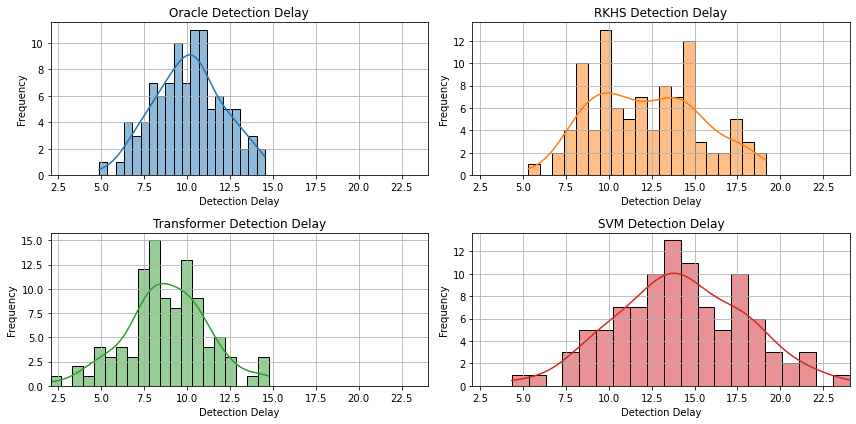

In [12]:
# Re-import required libraries after kernel reset
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Example synthetic detection delays for 4 methods (replace with real data)
np.random.seed(0)
detection_delays = {
    "Oracle": np.random.normal(loc=10, scale=2, size=100),
    "RKHS": np.random.normal(loc=12, scale=3, size=100),
    "Transformer": np.random.normal(loc=9, scale=2.5, size=100),
    "SVM": np.random.normal(loc=15, scale=4, size=100)
}

# Determine global x-axis limits across all histograms
all_delays = np.concatenate(list(detection_delays.values()))
x_min, x_max = np.min(all_delays), np.max(all_delays)

# Plot histograms with fixed x-axis
plt.figure(figsize=(12, 6))
for i, method in enumerate(detection_delays.keys()):
    plt.subplot(2, 2, i+1)
    sns.histplot(detection_delays[method], bins=20, kde=True, color=f'C{i}')
    plt.title(f'{method} Detection Delay')
    plt.xlabel('Detection Delay')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.xlim(x_min, x_max)

plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/all_models_DD.png", dpi=300, bbox_inches='tight')
plt.show()
